Compare 10, 20, and 50 coin flips
We plot the fraction of heads, not just the number of heads, so all three distributions are centered around 0.5.

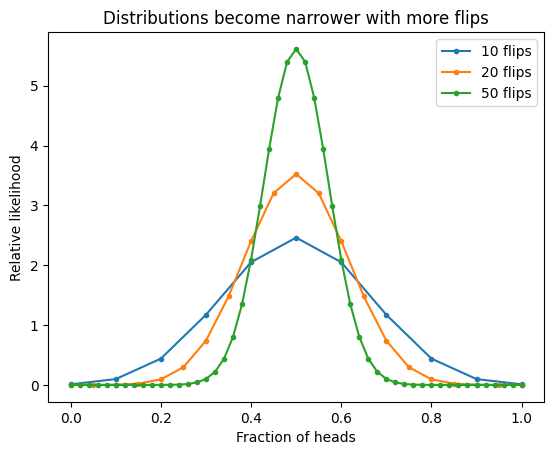

In [1]:
import matplotlib.pyplot as plt
from math import comb

def coin_probabilities(n):
    heads = list(range(n + 1))
    probabilities = [comb(n, h) / (2 ** n) for h in heads]
    frequencies = [h / n for h in heads]
    return heads, frequencies, probabilities

for n in [10, 20, 50]:
    heads, frequencies, probabilities = coin_probabilities(n)
    plt.plot(frequencies, [n * p for p in probabilities], marker=".", label=f"{n} flips")
plt.xlabel("Fraction of heads")
plt.ylabel("Relative likelihood")
plt.title("Distributions become narrower with more flips")
plt.legend()
plt.show()

Calculate the chance of an extreme result
Following Chapter 1, an extreme result means at least 80% heads or at most 20% heads. We compute the probability for each number of flips.

In [2]:
for n in [10, 20, 50, 100]:
    heads, frequencies, probabilities = coin_probabilities(n)
    extreme_probability = sum(p for f, p in zip(frequencies, probabilities) if f <= 0.2 or f >= 0.8)
    print(f"{n} flips: P(extreme result) = {extreme_probability:.6f}")

10 flips: P(extreme result) = 0.109375
20 flips: P(extreme result) = 0.011818
50 flips: P(extreme result) = 0.000024
100 flips: P(extreme result) = 0.000000


Shade the extreme intervals
The highlighted tails become smaller relative to the central peak as the number of flips grows.

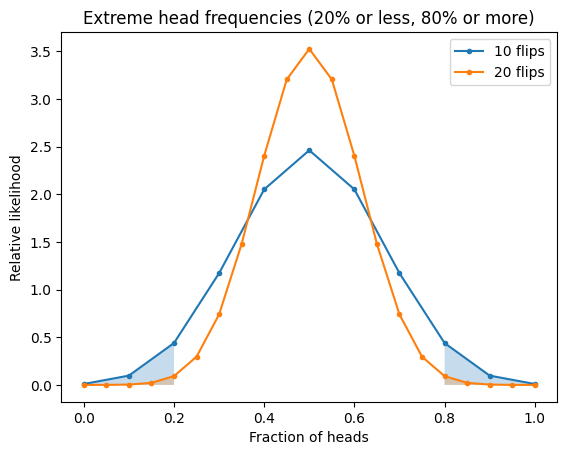

In [3]:
for n in [10, 20]:
    heads, frequencies, probabilities = coin_probabilities(n)
    likelihoods = [n * p for p in probabilities]
    plt.plot(frequencies, likelihoods, marker=".", label=f"{n} flips")
    plt.fill_between(frequencies, likelihoods, where=[f <= 0.2 or f >= 0.8 for f in frequencies], alpha=0.25)
plt.xlabel("Fraction of heads")
plt.ylabel("Relative likelihood")
plt.title("Extreme head frequencies (20% or less, 80% or more)")
plt.legend()
plt.show()

Answer
A fair coin has a 50% chance of heads on every flip. When we flip more coins, outcomes with a fraction of heads near 0.5 become more likely than very high or very low fractions. The graph becomes narrower around 0.5, so the chance of observing 80% or more heads (or 20% or fewer heads) decreases. This is an illustration of the law of large numbers. It does not mean extreme outcomes are impossible; they just become less likely.